<div dir="rtl"><h1>تمرین اول بینایی کامپیوتر</h1><p>علی اولیا (Ali Owlia)</p><p>سلول‌ها را از ابتدا به ترتیب اجرا کنید. گزارش Word شامل تحلیل کامل فارسی است.</p></div>

In [1]:
"""Computer Vision HW1 - Ali Owlia."""
from pathlib import Path
import json
import csv
import subprocess
import cv2
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

ROOT = Path.cwd()
DATA = ROOT / 'inputs'
OUT = ROOT / 'outputs'
OUT.mkdir(exist_ok=True)
SEED = 42

def u8(image):
    return np.clip(np.rint(image), 0, 255).astype(np.uint8)

def read_image(name, gray=False):
    image = cv2.imread(str(DATA / name), 0 if gray else 1)
    if image is None:
        raise FileNotFoundError(DATA / name)
    return image

def info(image):
    return dict(shape=list(image.shape), dtype=str(image.dtype), minimum=int(image.min()), maximum=int(image.max()), channels=1 if image.ndim == 2 else image.shape[2])

def grid(name, images, titles, cols=3, hist=False):
    rows = (len(images) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(4*cols, 3.4*rows), squeeze=False)
    for ax, im, title in zip(axes.flat, images, titles):
        if hist:
            ax.hist(im.ravel(), bins=256, range=(0,256), color='#366789')
            ax.set_xlim(0,255)
            ax.set_xlabel('Intensity'); ax.set_ylabel('Pixel count')
        else:
            ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB) if im.ndim == 3 else im, cmap='gray', vmin=0, vmax=255)
            ax.axis('off')
        ax.set_title(title, fontsize=11)
    for ax in list(axes.flat)[len(images):]:
        ax.axis('off')
    fig.tight_layout()
    fig.savefig(OUT / (name+'.png'), dpi=160)
    plt.close(fig)

def salt_pepper(image, density, rng):
    # Choose distinct spatial pixels, shared by all color channels.
    result = image.copy()
    count = int(round(image.shape[0]*image.shape[1]*density))
    places = rng.choice(image.shape[0]*image.shape[1], count, replace=False)
    flat = result.reshape((-1,) if image.ndim == 2 else (-1,image.shape[2]))
    flat[places[:count//2]] = 255
    flat[places[count//2:]] = 0
    return result

def spatial_filter(image, kernel):
    # Correlation convention matches OpenCV. Keep signed float results.
    kernel = np.asarray(kernel, dtype=np.float64)
    if kernel.ndim != 2 or any(k % 2 == 0 for k in kernel.shape):
        raise ValueError('Kernel dimensions must be odd.')
    h,w = image.shape[:2]
    ph,pw = kernel.shape[0]//2, kernel.shape[1]//2
    padding = ((ph,ph),(pw,pw)) + (((0,0),) if image.ndim == 3 else ())
    padded = np.pad(image.astype(float), padding, mode='edge')
    result = np.zeros_like(image, dtype=float)
    # Each shifted slice contributes one kernel coefficient.
    for y in range(kernel.shape[0]):
        for x in range(kernel.shape[1]):
            result += kernel[y,x]*padded[y:y+h,x:x+w]
    return result

def median_filter(image, size=3):
    if size < 1 or size % 2 == 0:
        raise ValueError('Median size must be positive and odd.')
    p = size//2
    padding = ((p,p),(p,p)) + (((0,0),) if image.ndim == 3 else ())
    padded = np.pad(image,padding,mode='edge')
    h,w = image.shape[:2]
    # Compute the order statistic directly; no library median filter.
    neighbors = np.stack([padded[y:y+h,x:x+w] for y in range(size) for x in range(size)])
    return np.sort(neighbors,axis=0)[size*size//2]

def gaussian_kernel(size=5, sigma=1.0):
    axis = np.arange(size)-size//2
    x,y = np.meshgrid(axis,axis)
    kernel = np.exp(-(x*x+y*y)/(2*sigma*sigma))
    return kernel/kernel.sum()

def psnr(reference, image):
    mse = np.mean((reference.astype(float)-image.astype(float))**2)
    return float('inf') if mse == 0 else float(10*np.log10(255**2/mse))

def save_csv(name, rows):
    with (OUT/name).open('w', newline='', encoding='utf-8-sig') as f:
        writer = csv.DictWriter(f,fieldnames=list(rows[0]))
        writer.writeheader(); writer.writerows(rows)

def part1():
    image = read_image('Peppers.png')
    gray = cv2.cvtColor(image,cv2.COLOR_BGR2GRAY)
    threshold,binary = cv2.threshold(gray,0,255,cv2.THRESH_BINARY+cv2.THRESH_OTSU)
    hsv = cv2.cvtColor(image,cv2.COLOR_BGR2HSV)
    grid('01_types',[image,gray,binary],['RGB display','Grayscale',f'Binary: Otsu = {threshold:.0f}'])
    grid('02_channels',[image[:,:,2],image[:,:,1],image[:,:,0],hsv[:,:,0],hsv[:,:,1],hsv[:,:,2]],['R','G','B','H (0-179)','S','V'])
    lower = np.array([35,65,60]); upper = np.array([85,255,255])
    def mask(im):
        return cv2.inRange(cv2.cvtColor(im,cv2.COLOR_BGR2HSV),lower,upper)
    original_mask = mask(image)
    grid('03_green',[image,original_mask,cv2.bitwise_and(image,image,mask=original_mask)],['Original','Green mask','Selected regions'])
    high = u8((gray.astype(float)-gray.mean())*1.5+gray.mean())
    low = u8((gray.astype(float)-gray.mean())*0.5+gray.mean())
    contrasts = [float(np.std(im)) for im in [gray,high,low]]
    assert contrasts[1] > contrasts[0] > contrasts[2]
    grid('04_contrast',[gray,high,low],[f'{n}: RMS = {v:.2f}' for n,v in zip(['Original','High','Low'],contrasts)])
    grid('05_contrast_hist',[gray,high,low],['Original','High contrast','Low contrast'],hist=True)
    dark_hsv = hsv.copy(); dark_hsv[:,:,2] = u8(hsv[:,:,2]*0.3)
    dark = cv2.cvtColor(dark_hsv,cv2.COLOR_HSV2BGR)
    def enhance(equalize):
        channels = cv2.cvtColor(dark,cv2.COLOR_BGR2HSV)
        v = channels[:,:,2]
        channels[:,:,2] = cv2.equalizeHist(v) if equalize else u8((v.astype(float)-v.min())*255/max(1,int(v.max())-int(v.min())))
        return cv2.cvtColor(channels,cv2.COLOR_HSV2BGR)
    equalized,stretched = enhance(True),enhance(False)
    variants = [image,dark,equalized,stretched]
    labels = ['Original','Dark (V x 0.3)','Equalization on V','Stretching on V']
    grid('06_lighting',variants,labels,cols=2)
    grid('07_lighting_hist',[cv2.cvtColor(im,cv2.COLOR_BGR2GRAY) for im in variants],labels,cols=2,hist=True)
    masks = [mask(im) for im in variants]
    grid('08_masks',masks,labels,cols=2)
    grid('09_masked',[cv2.bitwise_and(im,im,mask=m) for im,m in zip(variants,masks)],labels,cols=2)
    rows=[]
    for name,m in zip(labels,masks):
        union = np.count_nonzero((m>0)|(original_mask>0))
        rows.append(dict(version=name,pixels=int(np.count_nonzero(m)),iou_to_original=float(np.count_nonzero((m>0)&(original_mask>0))/max(1,union))))
    save_csv('segmentation.csv',rows)
    return dict(image=info(image),threshold=threshold,contrast=contrasts,hsv_lower=lower.tolist(),hsv_upper=upper.tolist(),segmentation=rows)

SX = np.array([[-1,0,1],[-2,0,2],[-1,0,1]],float)
SY = SX.T
LAP = np.array([[0,1,0],[1,-4,1],[0,1,0]],float)

def edges(image, builtin=False):
    if builtin:
        x=cv2.Sobel(image,cv2.CV_64F,1,0,ksize=3,borderType=cv2.BORDER_REPLICATE)
        y=cv2.Sobel(image,cv2.CV_64F,0,1,ksize=3,borderType=cv2.BORDER_REPLICATE)
        lap=cv2.Laplacian(image,cv2.CV_64F,ksize=1,borderType=cv2.BORDER_REPLICATE)
    else:
        x,y,lap=[spatial_filter(image,k) for k in [SX,SY,LAP]]
    return np.hypot(x,y),lap

def part2():
    raw=read_image('scanned_document.png')
    original=cv2.cvtColor(raw,cv2.COLOR_BGR2GRAY)
    rng=np.random.default_rng(SEED)
    noisy={'Salt-pepper':salt_pepper(original,0.05,rng),'Gaussian':u8(original.astype(float)+rng.normal(0,20,original.shape))}
    grid('10_noise',[original,*noisy.values()],['Original','Salt-pepper 5%','Gaussian sigma=20'])
    kernels={'Mean':np.ones((3,3))/9,'Gaussian':gaussian_kernel()}
    rows=[]; differences=[]; median=None
    for noise,im in noisy.items():
        manual={name:u8(spatial_filter(im,k)) for name,k in kernels.items()}
        manual['Median']=median_filter(im)
        builtin={'Mean':u8(cv2.blur(im.astype(float),(3,3),borderType=cv2.BORDER_REPLICATE)),
                 'Gaussian':u8(cv2.GaussianBlur(im.astype(float),(5,5),1.0,borderType=cv2.BORDER_REPLICATE)),
                 'Median':cv2.medianBlur(im,3)}
        rows.append(dict(noise=noise,method='Noisy',manual_psnr=psnr(original,im),opencv_psnr=psnr(original,im)))
        for name in manual:
            rows.append(dict(noise=noise,method=name,manual_psnr=psnr(original,manual[name]),opencv_psnr=psnr(original,builtin[name])))
            diff=np.abs(manual[name].astype(float)-builtin[name].astype(float))
            differences.append(dict(input=noise,filter=name,mae=float(diff.mean()),max_error=float(diff.max())))
            assert diff.max() <= 1
        grid('11_'+noise,[original,im,manual['Mean'],manual['Gaussian'],manual['Median'],builtin['Median']],['Original','Noisy','Manual mean 3x3','Manual Gaussian 5x5','Manual median 3x3','OpenCV median'],cols=3)
        grid('12_'+noise,[*manual.values(),*builtin.values()],['Manual '+x for x in manual]+['OpenCV '+x for x in builtin],cols=3)
        if noise=='Salt-pepper': median=manual['Median']
    for label,im in [('original',original),('noisy',noisy['Salt-pepper']),('restored',median)]:
        manual=edges(im); builtin=edges(im,True)
        for name,a,b in zip(['Sobel','Laplacian'],manual,builtin):
            diff=np.abs(a-b)
            differences.append(dict(input=label,filter=name,mae=float(diff.mean()),max_error=float(diff.max())))
            assert np.allclose(a,b,atol=1e-9)
        # A fixed scale makes the three inputs visually comparable.
        grid('13_edges_'+label,[im,u8(manual[0]/4),u8(np.abs(manual[1])/4),im,u8(builtin[0]/4),u8(np.abs(builtin[1])/4)],['Input','Manual Sobel /4','Manual |Laplacian| /4','Input','OpenCV Sobel /4','OpenCV |Laplacian| /4'])
    save_csv('psnr.csv',rows); save_csv('manual_vs_opencv.csv',differences)
    return dict(raw=info(raw),gray=info(original),psnr=rows,differences=differences)

def video_info(path, count_decode=False):
    cap=cv2.VideoCapture(str(path))
    if not cap.isOpened(): raise RuntimeError('Cannot open '+str(path))
    result=dict(width=int(cap.get(3)),height=int(cap.get(4)),fps=float(cap.get(5)),frames=int(cap.get(7)))
    result['duration']=result['frames']/result['fps']
    if count_decode:
        count=0
        while True:
            ok,frame=cap.read()
            if not ok: break
            assert frame.shape[:2]==(result['height'],result['width'])
            count+=1
        result['decoded_frames']=count
        assert count==result['frames']
    cap.release()
    return result

def part3():
    import imageio_ffmpeg
    source=DATA/'park_video.mp4'; meta=video_info(source)
    rng=np.random.default_rng(SEED+1)
    names=['noisy_video.mp4','filtered_video_1.mp4','filtered_video_2.mp4']
    def writer(name):
        command=[imageio_ffmpeg.get_ffmpeg_exe(),'-y','-loglevel','error','-f','rawvideo','-pix_fmt','bgr24','-s',f"{meta['width']}x{meta['height']}",'-r',str(meta['fps']),'-i','-','-an','-c:v','libx264','-preset','fast','-crf','18','-pix_fmt','yuv420p','-movflags','+faststart',str(ROOT/name)]
        return subprocess.Popen(command,stdin=subprocess.PIPE)
    # Use high-quality H.264 for practical size and broad playback support.
    cap=cv2.VideoCapture(str(source)); output=writer(names[0]); count=0
    try:
        while True:
            ok,frame=cap.read()
            if not ok: break
            output.stdin.write(salt_pepper(frame,0.05,rng).tobytes()); count+=1
    finally:
        cap.release(); output.stdin.close()
    assert output.wait()==0 and count==meta['frames']
    cap=cv2.VideoCapture(str(ROOT/names[0])); writers=[writer(n) for n in names[1:]]
    try:
        while True:
            ok,frame=cap.read()
            if not ok: break
            # Both methods receive the same decoded noisy frame.
            writers[0].stdin.write(cv2.medianBlur(frame,3).tobytes())
            writers[1].stdin.write(cv2.GaussianBlur(frame,(5,5),1,borderType=cv2.BORDER_REPLICATE).tobytes())
    finally:
        cap.release()
        for output in writers: output.stdin.close()
    for output in writers: assert output.wait()==0
    checks={n:video_info(ROOT/n,True) for n in names}
    for check in checks.values():
        assert check['width']==meta['width'] and check['height']==meta['height'] and check['frames']==meta['frames']
        assert abs(check['fps']-meta['fps'])<1e-5
    indices=[0,meta['frames']//2,meta['frames']-1]; rows=[]
    for index in indices:
        frames=[]
        for path in [source,*[ROOT/n for n in names]]:
            cap=cv2.VideoCapture(str(path)); cap.set(cv2.CAP_PROP_POS_FRAMES,index)
            ok,frame=cap.read(); cap.release()
            assert ok; frames.append(frame)
        grid('14_frame_'+str(index),frames,['Original','Noisy 5%','Median 3x3','Gaussian 5x5'],cols=2)
        rows.append(dict(frame=index,noisy_psnr=psnr(frames[0],frames[1]),median_psnr=psnr(frames[0],frames[2]),gaussian_psnr=psnr(frames[0],frames[3])))
    save_csv('video_sample_psnr.csv',rows)
    return dict(input=meta,outputs=checks,samples=rows,noise_density=0.05,audio='Outputs contain video only')

def test_filters():
    rng=np.random.default_rng(42)
    for shape in [(9,11),(9,11,3)]:
        im=rng.integers(0,256,shape,dtype=np.uint8)
        for size in [(3,3),(5,5),(3,5),(1,1)]:
            kernel=rng.normal(size=size)
            assert np.allclose(spatial_filter(im,kernel),cv2.filter2D(im.astype(float),-1,kernel,borderType=cv2.BORDER_REPLICATE))
        assert np.array_equal(median_filter(im),cv2.medianBlur(im,3))
    im=np.full((100,100,3),127,np.uint8)
    noisy=salt_pepper(im,.05,rng)
    assert np.count_nonzero(np.any(noisy!=im,axis=2))==500
    assert np.count_nonzero(noisy[:,:,0]==0)==250
    print('Filter, boundary, signed-output and noise-density checks passed.')



In [2]:
test_filters()

Filter, boundary, signed-output and noise-density checks passed.


<div dir="rtl"><h2>بخش اول</h2></div>

In [3]:
part1_results = part1()
print(json.dumps(part1_results, indent=2))

{
  "image": {
    "shape": [
      1024,
      1536,
      3
    ],
    "dtype": "uint8",
    "minimum": 0,
    "maximum": 255,
    "channels": 3
  },
  "threshold": 116.0,
  "contrast": [
    48.591180980101235,
    70.65064286447314,
    24.297139225087335
  ],
  "hsv_lower": [
    35,
    65,
    60
  ],
  "hsv_upper": [
    85,
    255,
    255
  ],
  "segmentation": [
    {
      "version": "Original",
      "pixels": 144136,
      "iou_to_original": 1.0
    },
    {
      "version": "Dark (V x 0.3)",
      "pixels": 2352,
      "iou_to_original": 0.01524024700427614
    },
    {
      "version": "Equalization on V",
      "pixels": 42116,
      "iou_to_original": 0.2814123248181962
    },
    {
      "version": "Stretching on V",
      "pixels": 148846,
      "iou_to_original": 0.9683565564408853
    }
  ]
}


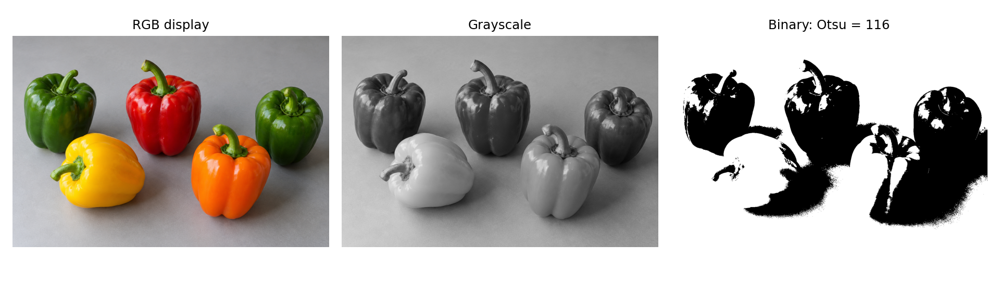

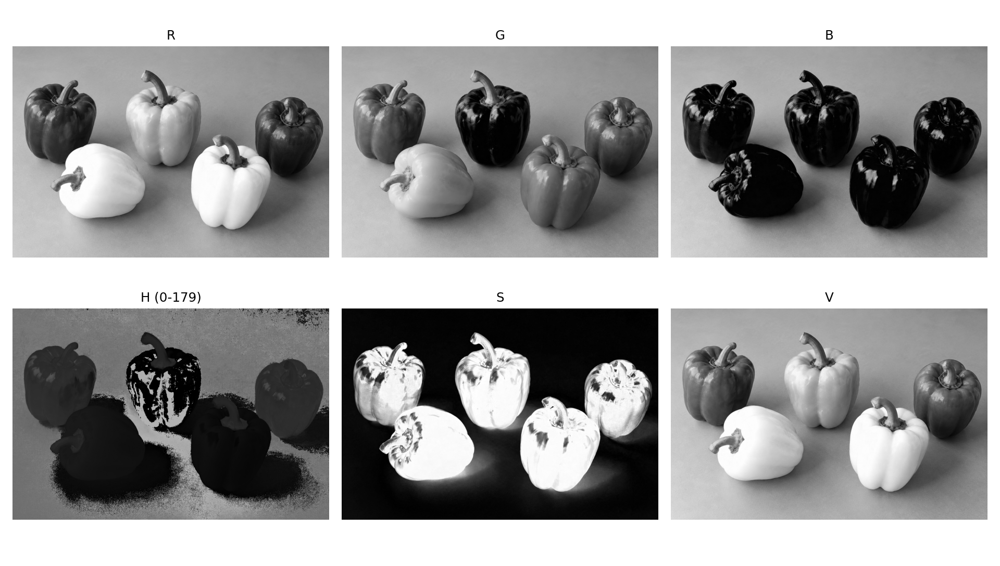

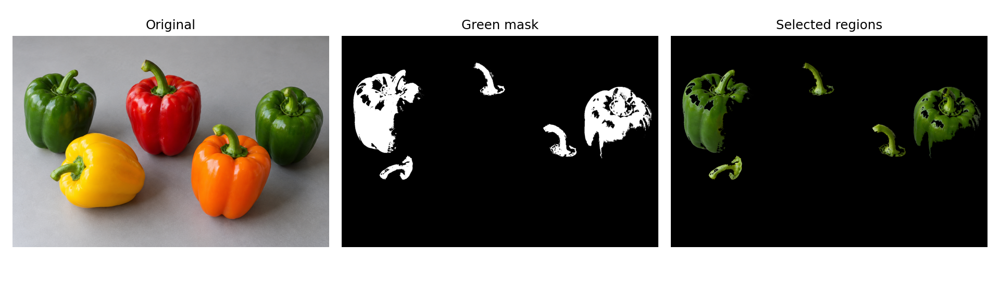

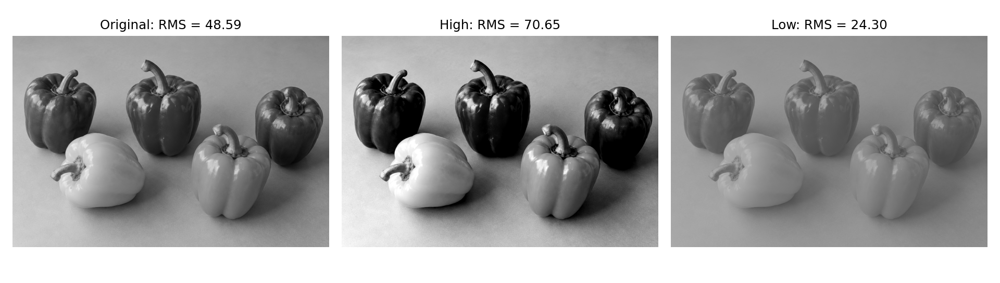

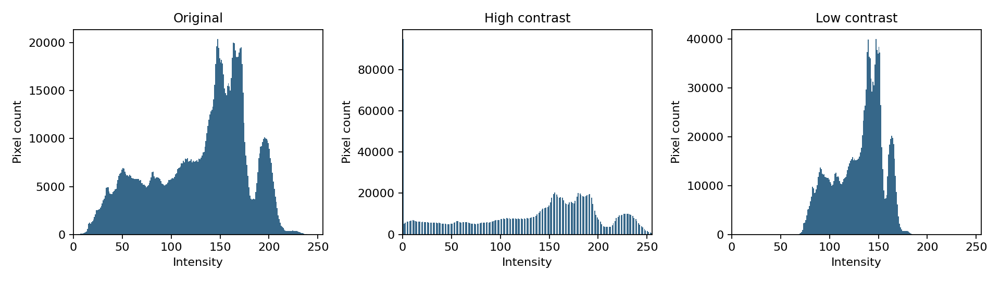

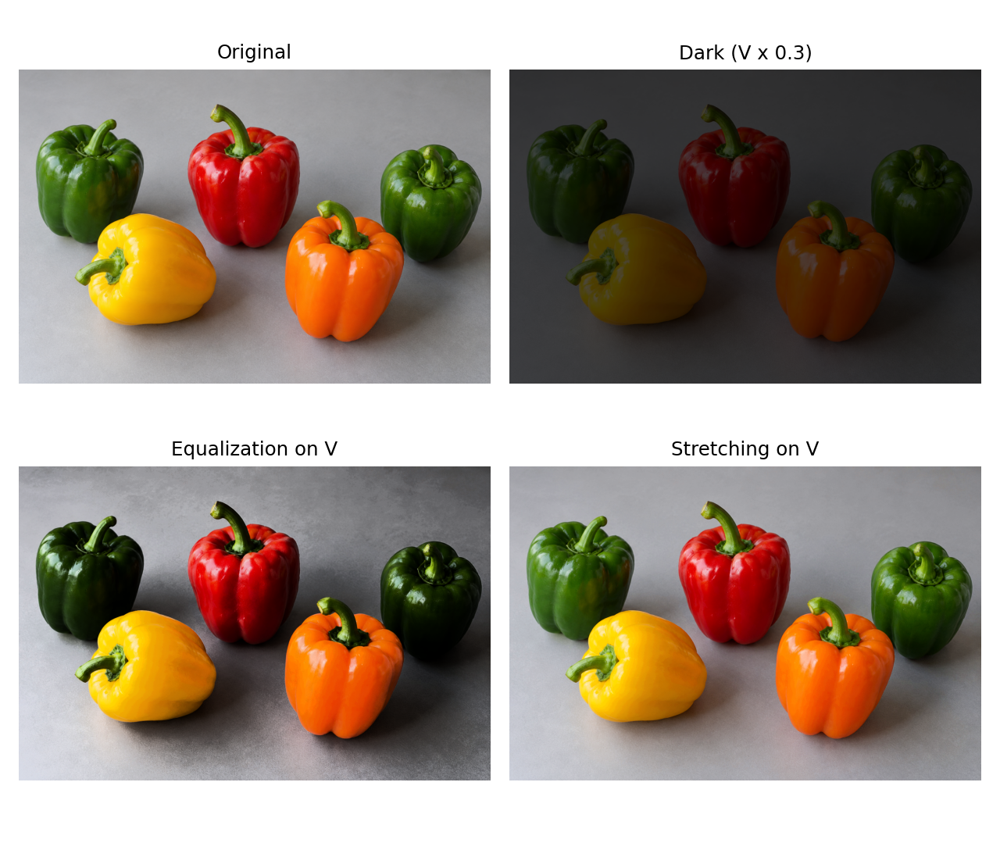

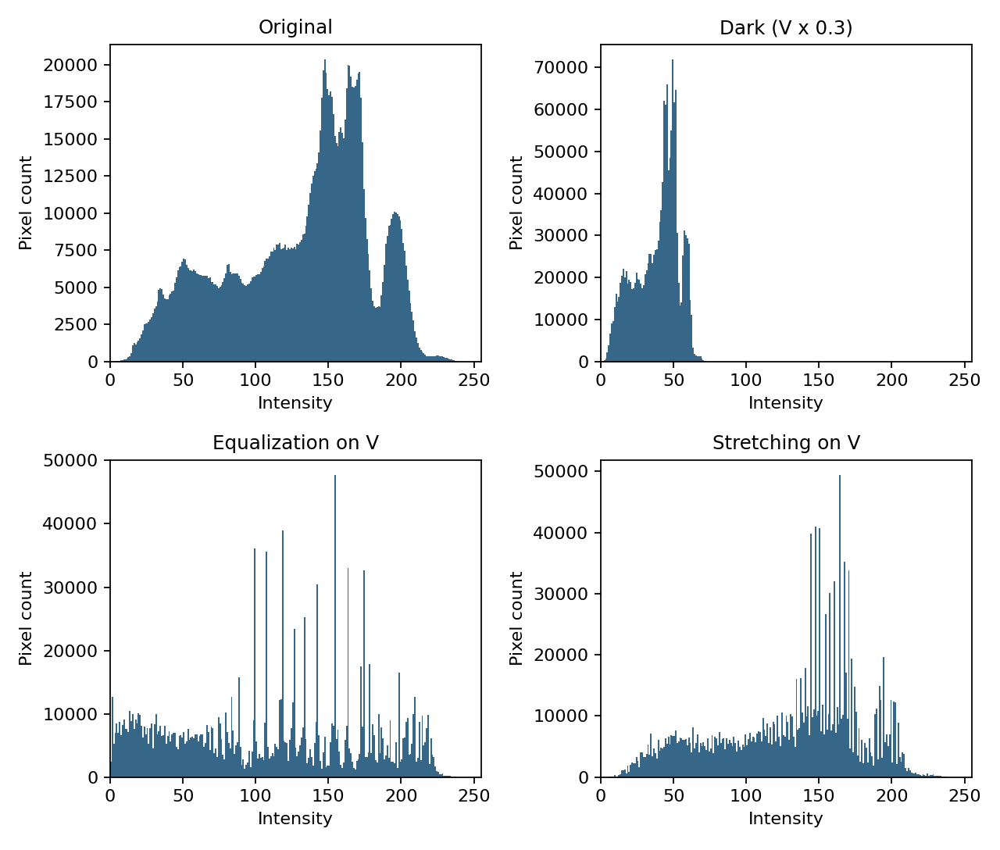

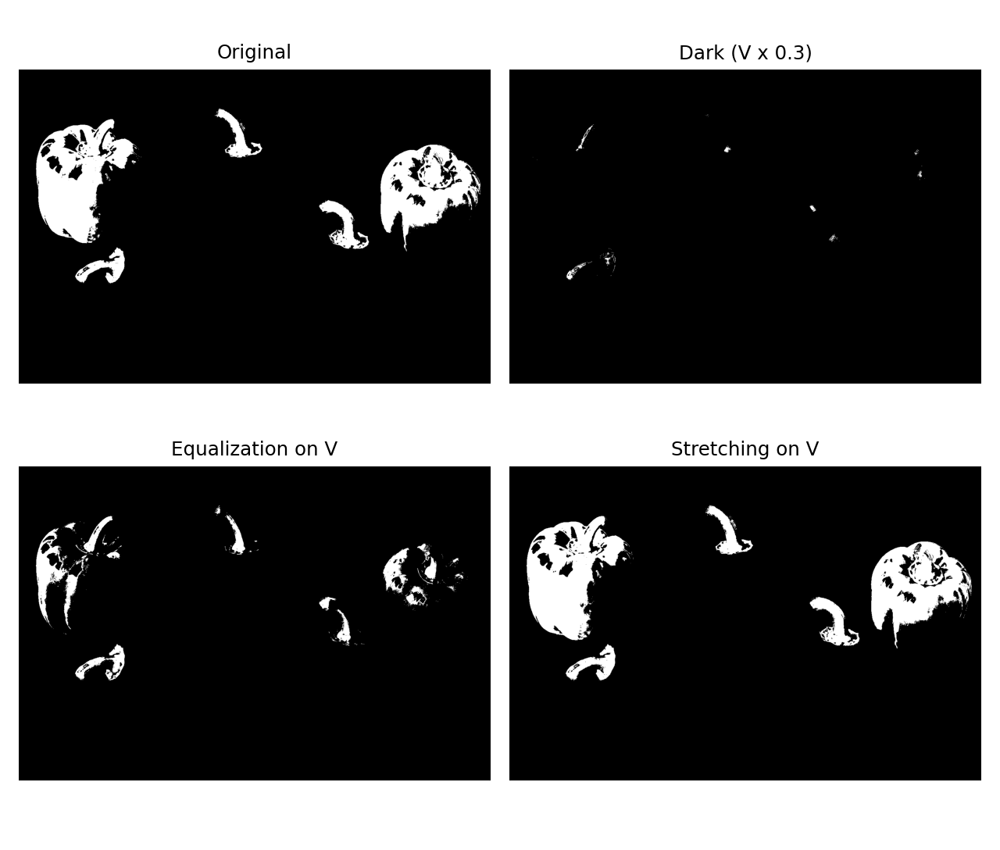

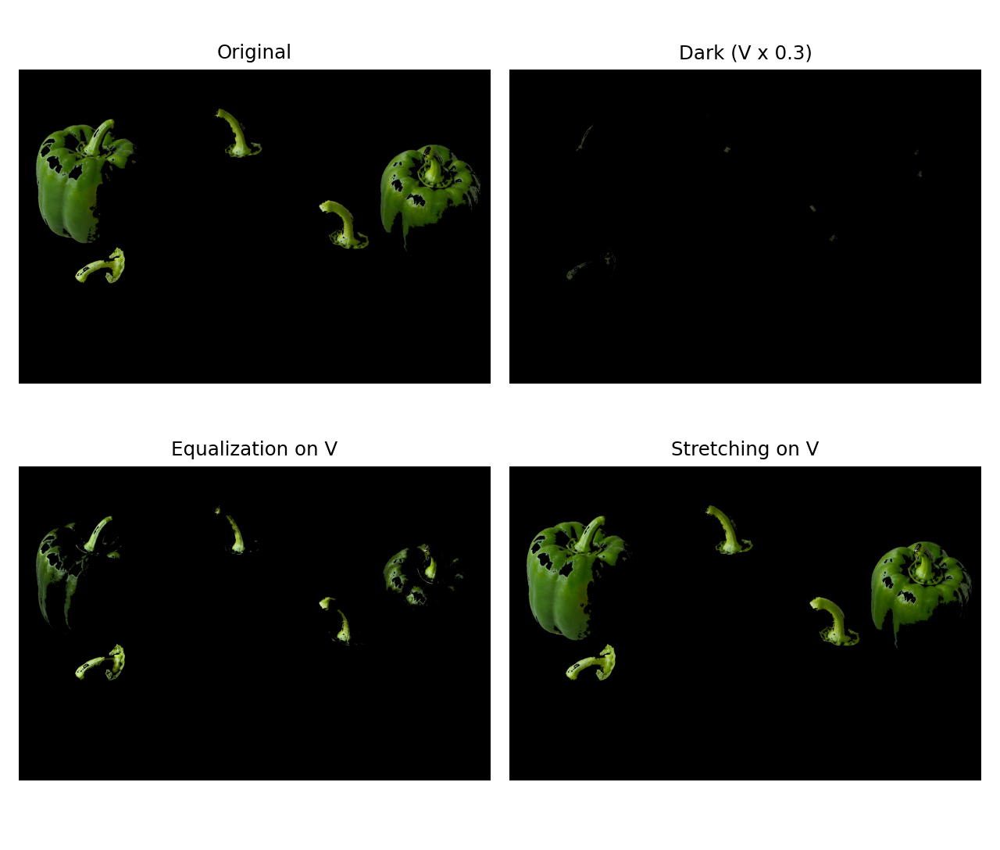

In [4]:
from IPython.display import display, Image
for path in sorted(OUT.glob('*.png')):
    if path.name.startswith(('0',)):
        display(Image(filename=str(path)))

<div dir="rtl"><h2>بخش دوم</h2></div>

In [5]:
part2_results = part2()
print(json.dumps(part2_results, indent=2))

{
  "raw": {
    "shape": [
      2048,
      2048,
      3
    ],
    "dtype": "uint8",
    "minimum": 23,
    "maximum": 248,
    "channels": 3
  },
  "gray": {
    "shape": [
      2048,
      2048
    ],
    "dtype": "uint8",
    "minimum": 30,
    "maximum": 248,
    "channels": 1
  },
  "psnr": [
    {
      "noise": "Salt-pepper",
      "method": "Noisy",
      "manual_psnr": 16.350077151780575,
      "opencv_psnr": 16.350077151780575
    },
    {
      "noise": "Salt-pepper",
      "method": "Mean",
      "manual_psnr": 23.77392150717904,
      "opencv_psnr": 23.77392150717904
    },
    {
      "noise": "Salt-pepper",
      "method": "Gaussian",
      "manual_psnr": 24.637860563735543,
      "opencv_psnr": 24.637860563735543
    },
    {
      "noise": "Salt-pepper",
      "method": "Median",
      "manual_psnr": 36.536357507620345,
      "opencv_psnr": 36.536357507620345
    },
    {
      "noise": "Gaussian",
      "method": "Noisy",
      "manual_psnr": 24.435154296807127,


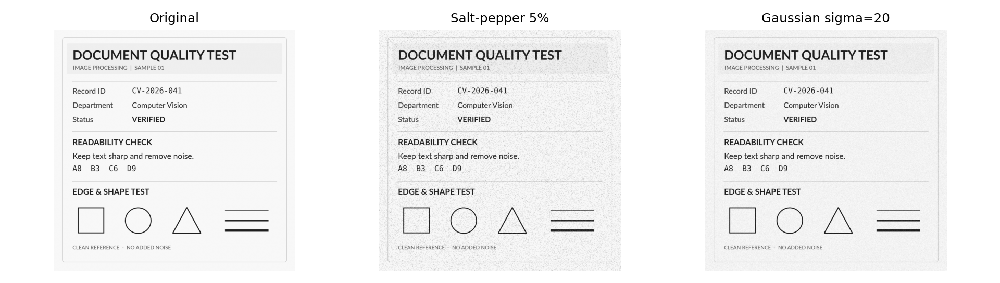

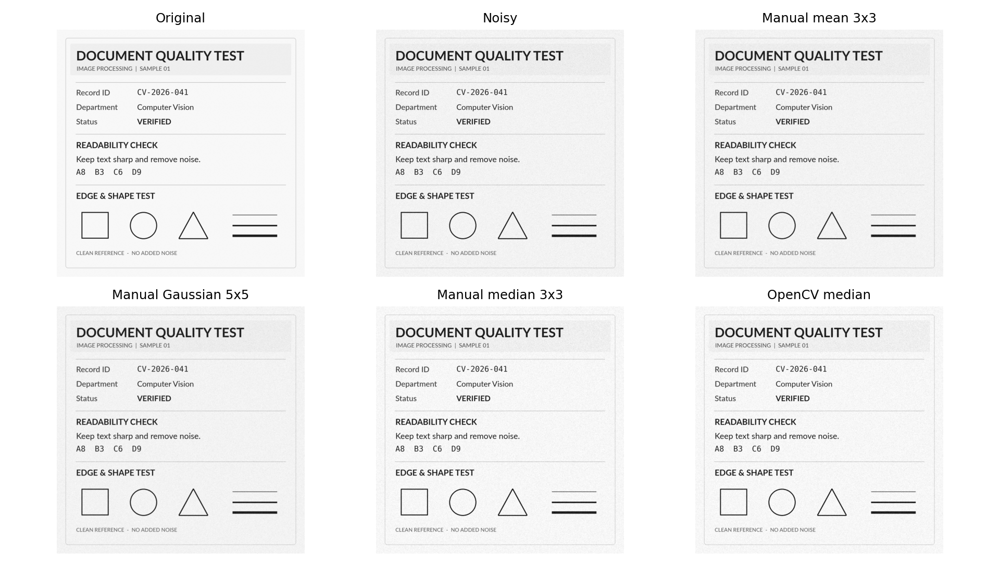

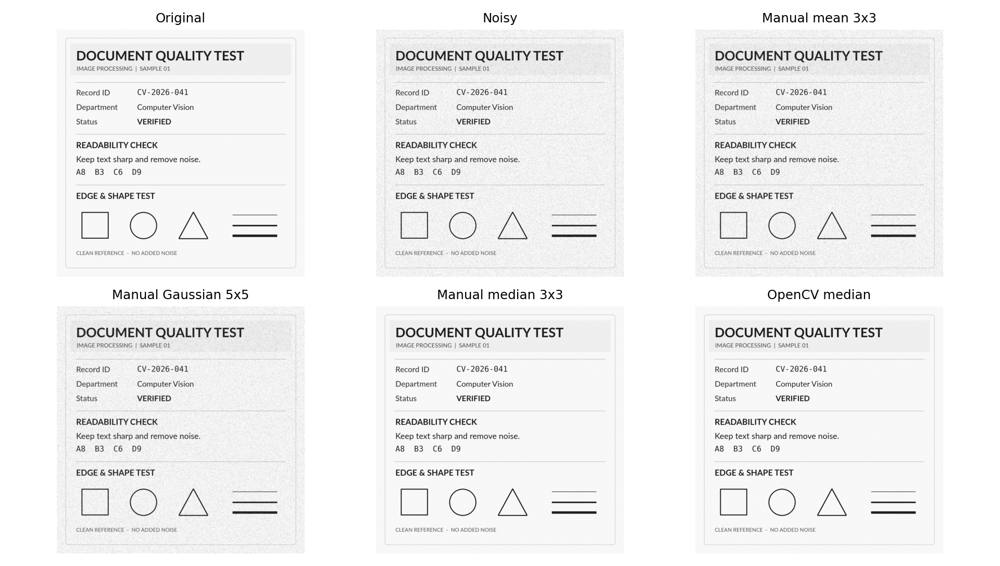

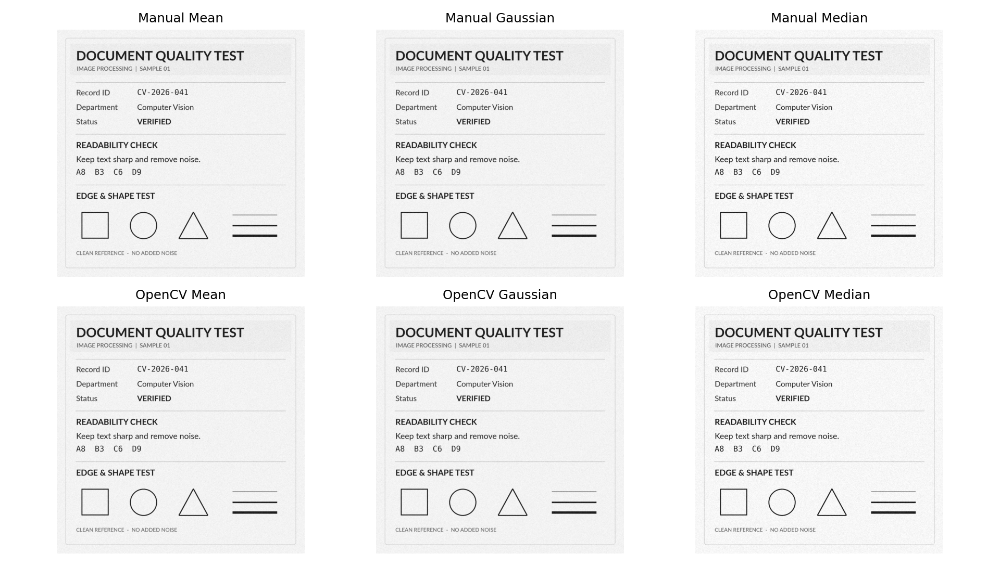

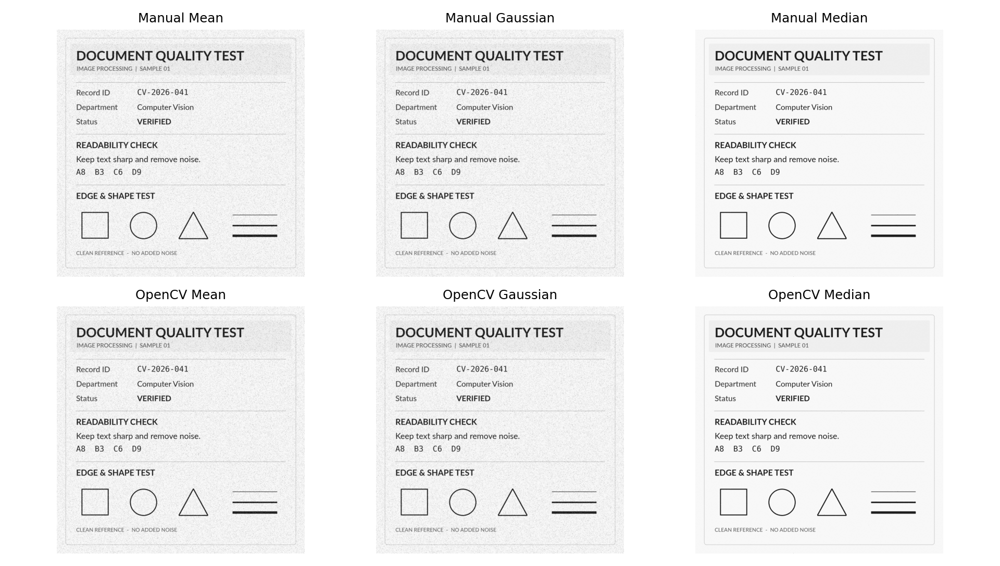

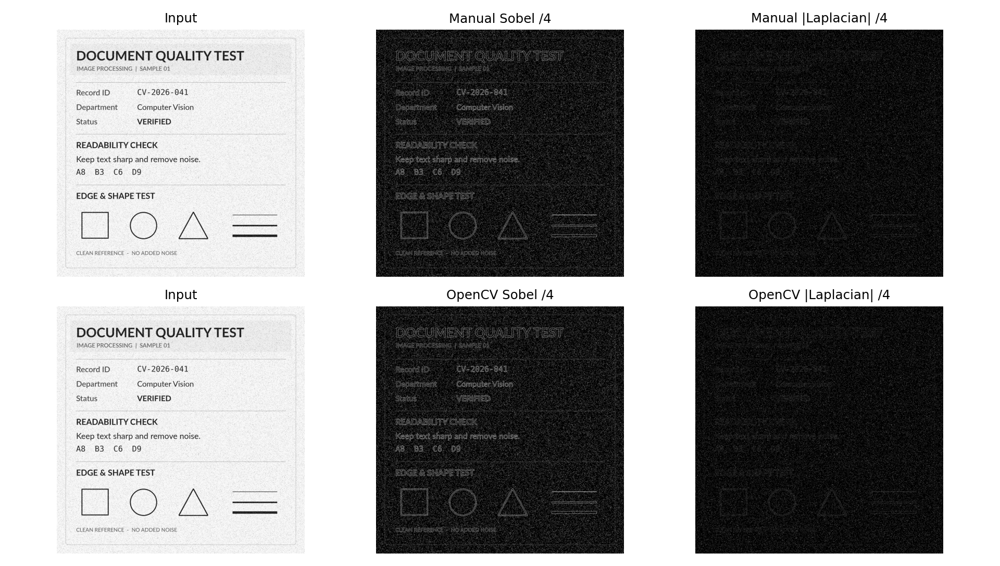

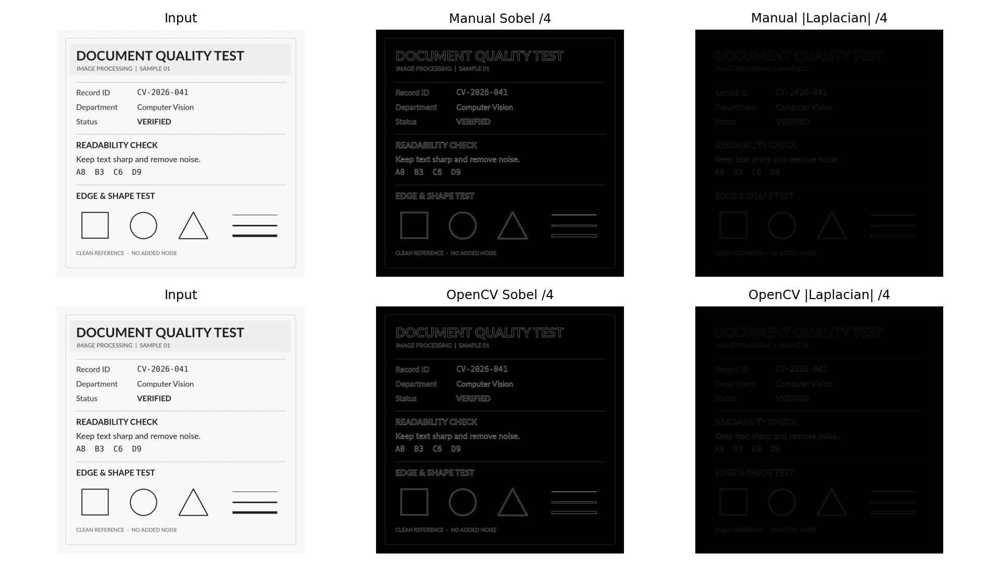

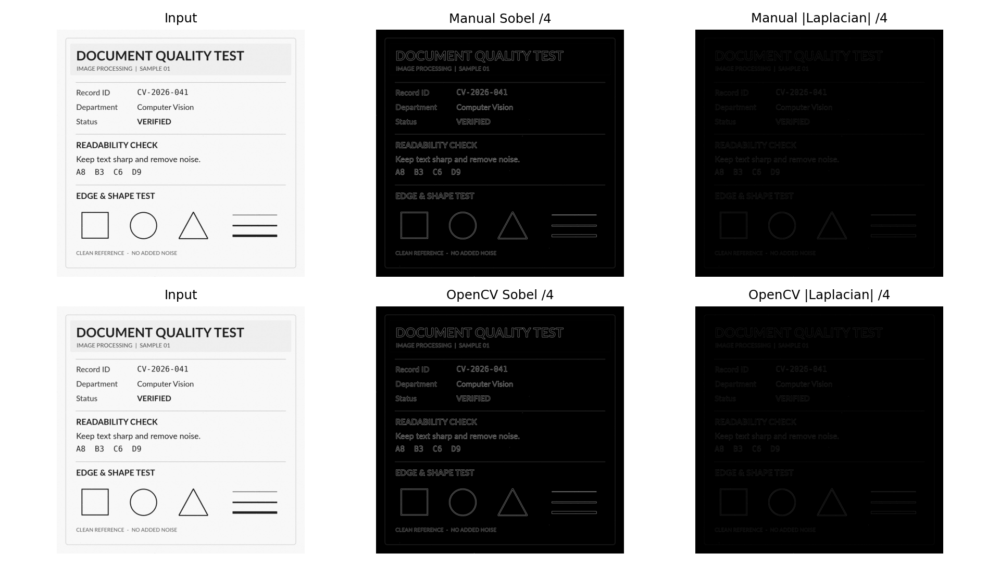

In [6]:
from IPython.display import display, Image
for path in sorted(OUT.glob('*.png')):
    if path.name.startswith(('10', '11', '12', '13')):
        display(Image(filename=str(path)))

<div dir="rtl"><h2>بخش سوم</h2></div>

In [7]:
part3_results = part3()
print(json.dumps(part3_results, indent=2))

{
  "input": {
    "width": 1280,
    "height": 720,
    "fps": 30.0,
    "frames": 450,
    "duration": 15.0
  },
  "outputs": {
    "noisy_video.mp4": {
      "width": 1280,
      "height": 720,
      "fps": 30.0,
      "frames": 450,
      "duration": 15.0,
      "decoded_frames": 450
    },
    "filtered_video_1.mp4": {
      "width": 1280,
      "height": 720,
      "fps": 30.0,
      "frames": 450,
      "duration": 15.0,
      "decoded_frames": 450
    },
    "filtered_video_2.mp4": {
      "width": 1280,
      "height": 720,
      "fps": 30.0,
      "frames": 450,
      "duration": 15.0,
      "decoded_frames": 450
    }
  },
  "samples": [
    {
      "frame": 0,
      "noisy_psnr": 17.545515940129228,
      "median_psnr": 24.608282563550535,
      "gaussian_psnr": 22.13928943912595
    },
    {
      "frame": 225,
      "noisy_psnr": 17.58380749234479,
      "median_psnr": 25.96972345185684,
      "gaussian_psnr": 22.98777854650762
    },
    {
      "frame": 449,
      "nois

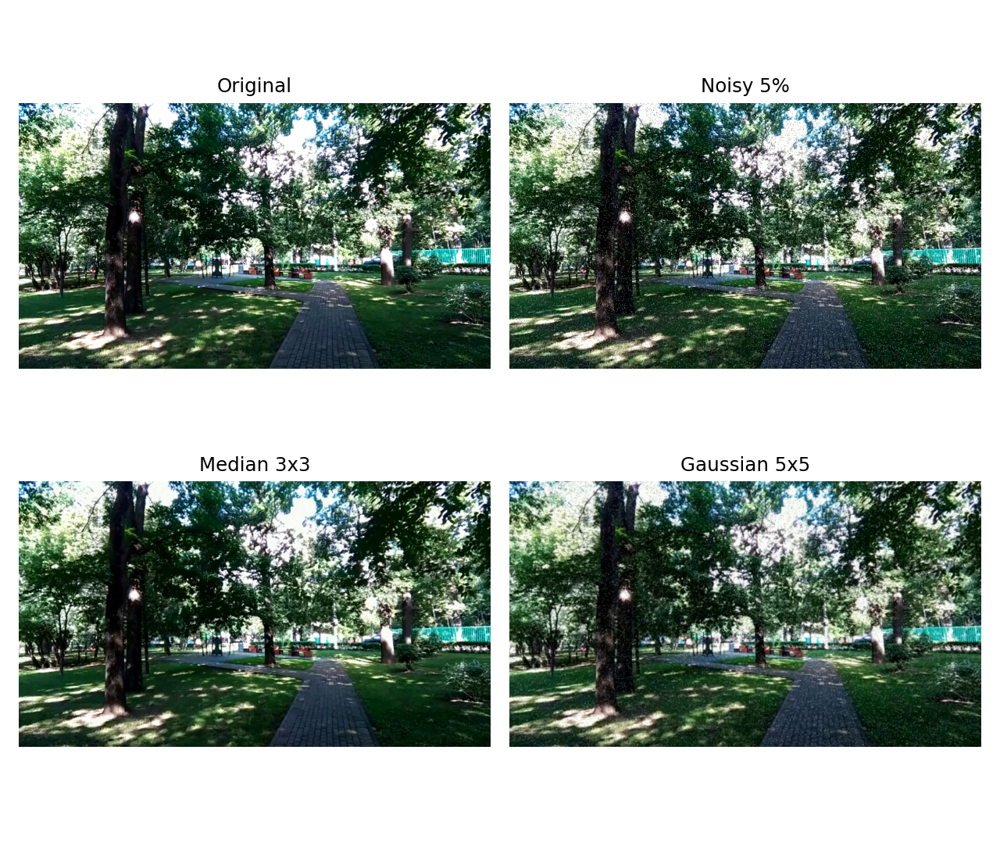

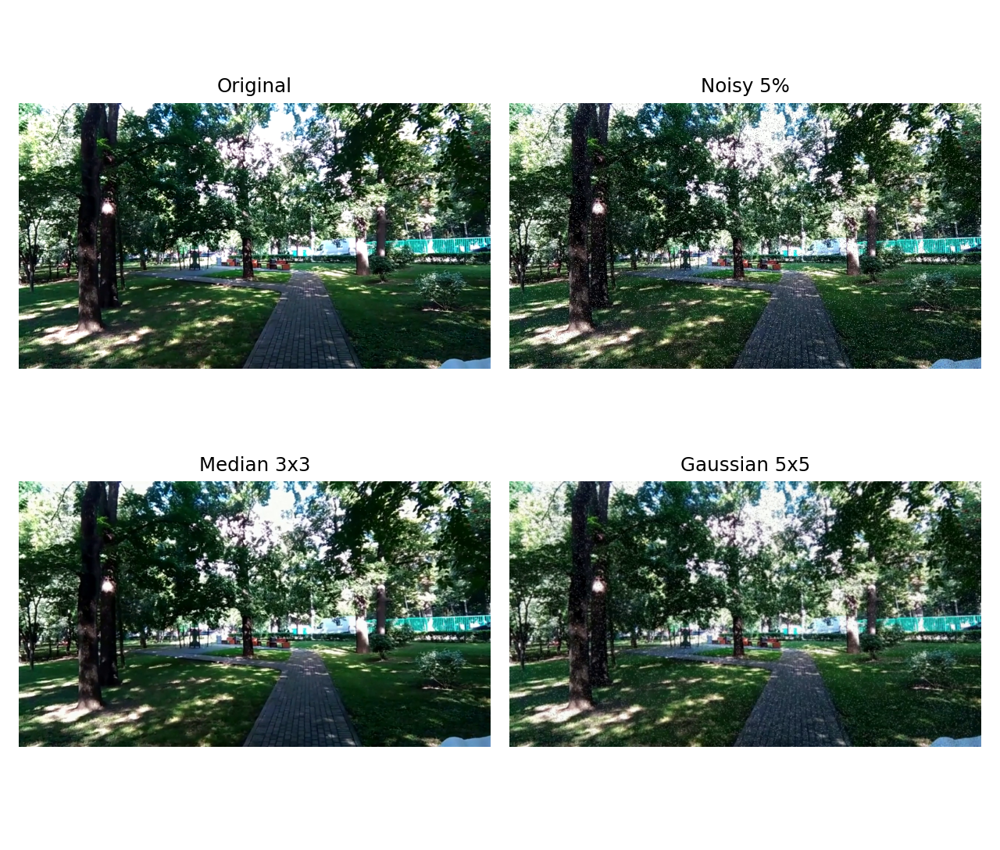

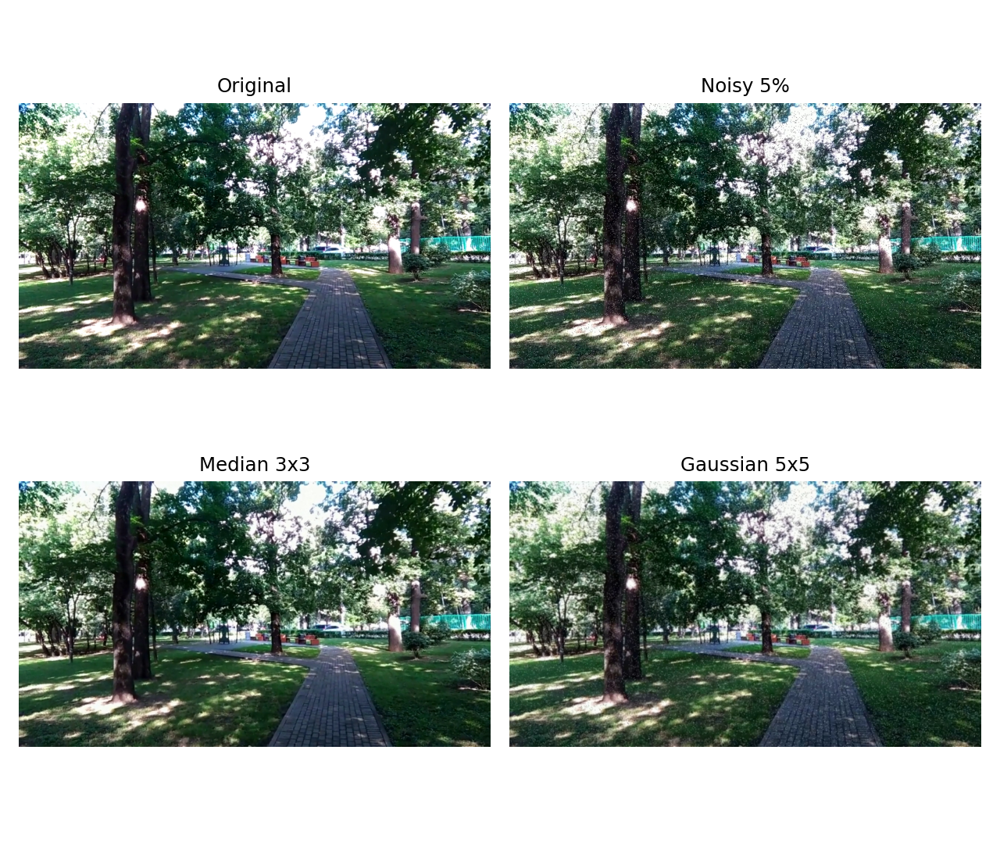

In [8]:
from IPython.display import display, Image
for path in sorted(OUT.glob('*.png')):
    if path.name.startswith(('14',)):
        display(Image(filename=str(path)))

<div dir="rtl"><h2>گزارش تمرین اول مبانی بینایی کامپیوتر</h2><p>علی اولیا (Ali Owlia)</p><p>دانشگاه تهران | نیمسال اول ۱۴۰۵ تا ۱۴۰۶</p><p>در این تمرین، ابتدا اثر روشنایی و کنتراست را بر جداسازی رنگ سبز بررسی کردم. سپس دو نوع نویز به تصویر سند اضافه کردم و نتیجه فیلترهای دستی را با توابع آماده مقایسه کردم. در بخش آخر، همین مسئله را روی تمام فریم‌های ویدئو دنبال کردم.</p><p>برای اینکه مقایسه‌ها قابل تکرار باشند، بذر تصادفی (Random Seed) ثابت است و هر روش، دقیقاً همان ورودی نویزدار را دریافت می‌کند. اعداد گزارش از اجرای کد استخراج شده‌اند؛ جدول‌های کامل و تصاویر با وضوح بیشتر نیز در پوشه خروجی قرار دارند.</p><p>نتیجه اصلی این است که انتخاب فیلتر به نوع نویز وابسته است. میانه (Median) برای نقاط ضربه‌ای مناسب است؛ اما برای قضاوت درباره حفظ جزئیات، باید هم عدد کیفیت و هم مرز حروف و اجسام را بررسی کرد.</p></div>

<div dir="rtl"><h2>۱ مشخصات تصویر و تبدیل انواع تصویر</h2><p>تصویر فلفل‌ها با ابعاد 1536 در 1024 پیکسل بارگذاری شد. نوع داده (Data Type) برابر uint8، تعداد کانال‌ها ۳ و محدوده مشاهده‌شده مقادیر از 0 تا 255 است. ترتیب ذخیره کانال‌ها در OpenCV برابر BGR است و برای نمایش به RGB تبدیل شده است.</p><p>برای تصویر دودویی (Binary)، ابتدا تصویر خاکستری (Grayscale) ساخته شد و سپس روش اتسو (Otsu) آستانه 116 را تعیین کرد. مقادیر بالاتر از آستانه سفید و بقیه سیاه شدند. اتسو آستانه را از هیستوگرام انتخاب می‌کند و جدایی دو گروه شدت را بیشینه می‌کند.</p><p>در تبدیل رنگی به خاکستری، تفاوت رنگ‌ها از بین می‌رود و فقط ترکیبی وزن‌دار از شدت کانال‌ها باقی می‌ماند. در تبدیل خاکستری به دودویی، طیف روشنایی نیز به دو مقدار محدود می‌شود؛ در نتیجه سایه‌ها، بافت ظریف و تغییرات تدریجی شدت از دست می‌روند.</p><p>در فضای رنگی (Color Space) مدل RGB، هر کانال مقدار یکی از رنگ‌های قرمز، سبز یا آبی را نشان می‌دهد. در مدل HSV، فام (Hue)، اشباع (Saturation) و مقدار روشنایی (Value) جدا هستند. بنابراین برای انتخاب یک رنگ، HSV معمولاً قابل تفسیرتر است. در OpenCV فام بین ۰ تا ۱۷۹ و دو کانال دیگر بین ۰ تا ۲۵۵ ذخیره می‌شوند. کانال فام در شکل با همان مقیاس ثابت خاکستری نمایش داده شده است.</p></div>

<div dir="rtl"><h2>۲ جداسازی نواحی سبز</h2><p>برای ساخت ماسک دودویی (Binary Mask)، بازه فام ۳۵ تا ۸۵، اشباع ۶۵ تا ۲۵۵ و روشنایی ۶۰ تا ۲۵۵ انتخاب شد. حداقل اشباع، پس‌زمینه خاکستری را کنار می‌گذارد و حداقل روشنایی از انتخاب پیکسل‌های بسیار تاریک جلوگیری می‌کند. این انتخاب مصالحه‌ای میان حذف پس‌زمینه و حفظ سایه‌های فلفل است.</p><p>ماسک، رنگ سبز را تشخیص می‌دهد و معنای جسم را نمی‌فهمد. به همین دلیل، ساقه سبز فلفل قرمز و نارنجی و زرد نیز می‌تواند انتخاب شود؛ همه نواحی سفید ماسک، متعلق به بدنه فلفل سبز نیستند. سایه‌های خیلی تیره و بازتاب‌های کم‌اشباع هم ممکن است حذف شوند.</p><p>در مراحل بعد، همین سه بازه بدون تغییر استفاده شده‌اند. در این آزمایش، عملیات پاک‌سازی شکلی به ماسک اضافه نشده است تا اثر تغییر روشنایی با اثر پردازش‌های دیگر مخلوط نشود.</p></div>

<div dir="rtl"><h2>۳ هیستوگرام و کنتراست</h2><p>هیستوگرام (Histogram) تعداد پیکسل‌ها را در هر سطح روشنایی نشان می‌دهد. پراکندگی شدت‌ها با کنتراست ارتباط دارد، اما محل پیکسل‌ها را مشخص نمی‌کند. به همین دلیل دو تصویر متفاوت می‌توانند هیستوگرام مشابه داشته باشند.</p><p>کنتراست مؤثر (RMS Contrast) در این گزارش، ریشه میانگین مربع فاصله شدت‌ها از میانگین تصویر است؛ این تعریف با انحراف معیار شدت خاکستری برابر است. مقیاس محاسبه ۰ تا ۲۵۵ است و نسخه نرمال‌شده با تقسیم بر ۲۵۵ به دست می‌آید.</p><p>برای افزایش و کاهش کنتراست، فاصله هر پیکسل از میانگین به‌ترتیب در ۱٫۵ و ۰٫۵ ضرب شد. سپس خروجی به محدوده معتبر محدود شد. کنتراست تصویر اصلی 48.591، نسخه پرکنتراست 70.651 و نسخه کم‌کنتراست 24.297 است. افزایش واقعی و کاهش واقعی این اعداد در کد کنترل می‌شود. محدودسازی شدت می‌تواند بخشی از اطلاعات نواحی بسیار روشن یا تاریک را حذف کند.</p></div>

<div dir="rtl"><h2>۴ بهبود تصویر در نور کم</h2><p>برای شبیه‌سازی نور کم، کانال روشنایی در HSV در ۰٫۳ ضرب شد. این یک مدل ساده از کاهش نور است و نویز حسگر و تغییر دمای رنگ را شبیه‌سازی نمی‌کند. سپس همسان‌سازی هیستوگرام (Histogram Equalization) و کشش هیستوگرام (Histogram Stretching) فقط روی کانال روشنایی اعمال شدند.</p><p>همسان‌سازی، شدت‌ها را با استفاده از توزیع تجمعی بازتوزیع می‌کند. کشش، کمینه و بیشینه روشنایی را با یک نگاشت خطی به ۰ و ۲۵۵ می‌برد. روش اول ممکن است ظاهر غیرطبیعی‌تری بدهد؛ روش دوم نسبت تغییرات را بهتر حفظ می‌کند، اما به کمینه و بیشینه حساس است.</p><p>دلیل پردازش یک کانال این است که تغییر مستقل قرمز و سبز و آبی می‌تواند نسبت رنگ‌ها را عوض کند. ثابت نگه‌داشتن فام و اشباع، رنگ را تا حد ممکن حفظ می‌کند؛ با این حال گردکردن مقادیر و تبدیل رفت‌وبرگشت می‌تواند تغییر کوچکی ایجاد کند.</p></div>

<div dir="rtl"><h2>۵ اثر بهبود روشنایی بر ماسک رنگ</h2><p>برای مقایسه عددی ماسک‌ها، نسبت اشتراک به اجتماع (Intersection over Union) نسبت به ماسک تصویر اصلی محاسبه شد. این عدد معیار پایداری در برابر تغییر نور است؛ چون برچسب واقعی نداریم، نباید آن را دقت تشخیص فلفل تعبیر کرد.</p><p>با تاریک‌شدن تصویر، بخشی از پیکسل‌های سبز از حداقل روشنایی ۶۰ پایین‌تر می‌روند. بهبود روشنایی می‌تواند تعدادی از آن‌ها را دوباره وارد ماسک کند. تفاوت دو روش را باید با همان آستانه ثابت بررسی کرد؛ تغییر آستانه برای هر تصویر، نتیجه این آزمایش را مخدوش می‌کند.</p><p>در این تصویر، شباهت ماسک پس از کشش 0.968 و پس از همسان‌سازی 0.281 است. بنابراین کشش، انتخاب رنگ را بهتر به حالت پیش از تاریک‌شدن برگردانده است. همسان‌سازی با تغییر غیرخطی روشنایی، تعداد بیشتری از سبزهای تیره را زیر آستانه نگه داشته است.</p></div>

<div dir="rtl"><h2>۶ توزیع روشنایی پس از بهبود</h2><p>نمودارهای زیر از شدت خاکستری تصاویر رنگی نهایی محاسبه شده‌اند، در حالی که عملیات بهبود روی کانال روشنایی HSV انجام شده است. بنابراین نباید انتظار داشت هیستوگرام خاکستری تصویر همسان‌شده کاملاً یکنواخت شود.</p><p>در نسخه تاریک، توزیع شدت به سمت مقادیر پایین جابه‌جا می‌شود. کشش بازه شدت را گسترش می‌دهد و همسان‌سازی شکل توزیع را تغییر می‌دهد. هیچ‌کدام اطلاعاتی را که در اثر گردکردن یا اشباع از بین رفته‌اند، واقعاً بازسازی نمی‌کنند.</p></div>

<div dir="rtl"><h2>۷ افزودن نویز به سند</h2><p>تصویر سند با ابعاد 2048 در 2048 پیکسل خوانده شد و برای بررسی خوانایی متن به خاکستری تبدیل شد. نوع داده uint8 و بازه شدت خاکستری 30 تا 248 است.</p><p>نویز نمک‌وفلفل (Salt and Pepper Noise) با چگالی ۵ درصد ساخته شد. مکان‌ها بدون تکرار انتخاب شدند و تقریباً نصف به صفر و نصف به ۲۵۵ تغییر کردند. این نویز ضربه‌ای است؛ یک پیکسل ناگهان مقدار شدیدی می‌گیرد. اگر پیکسل از ابتدا همین مقدار را داشته باشد، انتخاب آن الزاماً تغییر قابل مشاهده ایجاد نمی‌کند.</p><p>نویز گاوسی (Gaussian Noise) با میانگین صفر و انحراف معیار ۲۰، معادل واریانس ۴۰۰، به شدت تصویر اصلی اضافه شد. سپس شدت‌ها گرد و به بازه ۰ تا ۲۵۵ محدود شدند. نویز گاوسی شدت همه پیکسل‌ها را تغییر می‌دهد و پس از محدودسازی، به‌ویژه در نواحی روشن، دیگر دقیقاً توزیع گاوسی با میانگین صفر ندارد.</p><p>بذر تولید اعداد تصادفی برای تصاویر ثابت است. هر سه فیلتر، نسخه یکسانی از هر نویز را دریافت می‌کنند.</p></div>

<div dir="rtl"><h2>۸ پیاده‌سازی دستی و مقایسه فیلترهای پایین‌گذر</h2><p>هسته (Kernel) ماتریس کوچکی از وزن‌هاست که روی همسایگی پیکسل حرکت می‌کند. در فیلتر خطی، حاصل جمع ضرب وزن‌ها در شدت همسایه‌ها، مقدار جدید پیکسل را می‌سازد. تابع دستی از اندازه‌های فرد مختلف، از جمله هسته مستطیلی، پشتیبانی می‌کند و در مرزها نزدیک‌ترین پیکسل را تکرار می‌کند (Replicate Padding).</p><p>قرارداد تابع، همبستگی مکانی (Correlation) و سازگار با OpenCV است؛ در هم‌پیچی (Convolution) هسته باید برگردانده شود. برای هسته‌های متقارن میانگین و گاوسی این تفاوت اثری ندارد. در مشتق‌ها علامت مهم است، بنابراین پاسخ خام به‌صورت اعشاری علامت‌دار حفظ می‌شود.</p><p>فیلتر پایین‌گذر (Low-pass Filter) تغییرات سریع شدت را تضعیف می‌کند. میانگین ۳ در ۳ به هر همسایه وزن یک‌نهم می‌دهد. گاوسی ۵ در ۵ با انحراف معیار ۱ وزن بیشتری به مرکز می‌دهد؛ مجموع وزن‌ها برابر یک است. هیچ تابع آماده فیلترگذاری در مسیر دستی استفاده نشده است.</p><p>فیلتر میانه (Median Filter) غیرخطی است؛ ۹ مقدار پنجره ۳ در ۳ مرتب می‌شوند و مقدار میانی جایگزین مرکز می‌شود. این کار مقدارهای پرت را بهتر کنار می‌گذارد. برخلاف میانگین، نمی‌توان آن را با یک هسته ثابت کانولوشنی بیان کرد.</p></div>

<div dir="rtl"><h2>۹ مقایسه عددی کیفیت بازیابی</h2><p>نسبت اوج سیگنال به نویز (PSNR) از میانگین مربع خطای تصویر بازیابی‌شده نسبت به سند اصلی محاسبه می‌شود. مقدار آن ده برابر لگاریتم دهدهی نسبت مربع ۲۵۵ به میانگین مربع خطاست و واحد آن دسی‌بل (dB) است. مقدار بزرگ‌تر، خطای پیکسلی کمتر را نشان می‌دهد؛ ولی تضمین نمی‌کند مرز حروف بهتر حفظ شده باشد.</p><p>برای مقایسه منصفانه با OpenCV، اندازه هسته، انحراف معیار، مرزبندی و روش گردکردن یکسان هستند. فیلترهای خطی OpenCV روی داده اعشاری اجرا شده‌اند و سپس دقیقاً مانند مسیر دستی گرد شده‌اند. اختلاف‌های بسیار کوچک اعشاری ممکن است هنگام گردکردن یک واحد اختلاف ایجاد کنند.</p></div>

<div dir="rtl"><h2>۱۰ تحلیل تفاوت فیلترها</h2><p>در نویز نمک‌وفلفل، بهترین امتیاز متعلق به Median با مقدار 36.536 دسی‌بل است. در نویز گاوسی، بهترین امتیاز بین سه تنظیم آزمایش‌شده متعلق به Median با مقدار 30.157 دسی‌بل است. این نتیجه به همین تصویر و همین پارامترها مربوط است و حکم عمومی درباره همه تصاویر نیست.</p><p>میانگین و گاوسی، نقاط ضربه‌ای را به همسایه‌ها پخش می‌کنند و ممکن است لکه‌های محو بسازند. میانه، نقطه منفرد را اغلب حذف می‌کند؛ ولی وقتی چند پیکسل خراب در یک پنجره جمع شوند، حذف کامل تضمین نمی‌شود. خطوط بسیار باریک هم ممکن است با میانه آسیب ببینند.</p><p>در نویز گاوسی، میانگین‌گیری شدت نوسان‌ها را کاهش می‌دهد، اما مرز متن را نرم می‌کند. وزن‌دهی گاوسی معمولاً نسبت به میانگین یکنواخت، نقش مرکز را بیشتر حفظ می‌کند. اندازه پنجره‌ها در این تمرین یکسان نیست؛ بنابراین تفاوت نتیجه فقط ناشی از نام روش نیست.</p></div>

<div dir="rtl"><h2>۱۱ استخراج لبه و اثر نویز</h2><p>فیلتر بالاگذر (High-pass Filter) تغییرات سریع شدت را برجسته می‌کند. سوبل (Sobel) مشتق افقی و عمودی را با دو هسته ۳ در ۳ تقریب می‌زند و اندازه گرادیان از ریشه مجموع مربع دو پاسخ به دست می‌آید. لاپلاسین (Laplacian) مشتق دوم را با هسته چهارهمسایگی و ضریب مرکزی منفی چهار محاسبه می‌کند.</p><p>برای مقایسه، این دو روش روی تصویر اصلی، نسخه نمک‌وفلفلی و خروجی میانه اجرا شدند. نقاط نویز مرزهای کاذب ایجاد می‌کنند؛ به همین دلیل تصویر نویزدار پاسخ‌های فراوانی بیرون از مرز واقعی حروف دارد. میانه پیش از لبه‌یابی این پاسخ‌های کاذب را کاهش می‌دهد، ولی ممکن است جزئیات خیلی باریک را نیز تغییر دهد.</p><p>در نمایش سوبل، اندازه گرادیان و در نمایش لاپلاسین، قدرمطلق پاسخ بر چهار تقسیم شده‌اند. مقیاس برای هر سه حالت یکسان است. اعداد خام قبل از این تغییر نمایشی با OpenCV مقایسه می‌شوند.</p></div>

<div dir="rtl"><h2>۱۲ لبه‌های سند پس از حذف نویز</h2><p>در تصویر زیر، خروجی میانه ورودی مشترک هر دو پیاده‌سازی است. کاهش پاسخ‌های نقطه‌ای باعث می‌شود مرز حروف و شکل‌ها مشخص‌تر باشد. پاسخ لاپلاسین علامت‌دار است و فقط برای نمایش قدرمطلق آن گرفته شده است.</p><p>بیشترین اختلاف مطلق بین پاسخ‌های خام دستی و OpenCV برای سوبل و لاپلاسین برابر 0 است. بیشترین اختلاف بین خروجی فیلترهای پایین‌گذر برابر 0 سطح شدت است. جدول کامل خطای میانگین مطلق (MAE) و بیشینه خطا در فایل manual_vs_opencv.csv آمده است.</p></div>

<div dir="rtl"><h2>۱۳ پردازش و بازیابی ویدئو</h2><p>ویدئوی ورودی 450 فریم، نرخ فریم (FPS) برابر 30.0000، ابعاد 1280 در 720 و مدت 15.000 ثانیه دارد. تعداد فریم‌های خروجی با خواندن کامل هر فایل بررسی شده است.</p><p>روی تمام فریم‌ها، ۵ درصد مکان پیکسلی بدون تکرار انتخاب و تقریباً مساوی بین نمک و فلفل تقسیم شدند. کانال‌های هر مکان هم‌زمان تغییر کردند تا نقاط سیاه یا سفید ساخته شوند. خروجی این مرحله noisy_video.mp4 است.</p><p>ویدئوی نویزدار ذخیره‌شده دوباره خوانده شد. فیلتر میانه ۳ در ۳ خروجی filtered_video_1.mp4 و فیلتر گاوسی ۵ در ۵ با انحراف معیار ۱ خروجی filtered_video_2.mp4 را ساختند. هر دو مستقلاً روی همان فریم نویزدار اجرا شدند. در بخش ویدئو از توابع آماده استفاده شد؛ الزام پیاده‌سازی دستی مربوط به بخش دوم است.</p><p>ویدئوها با کدگذاری H.264 و تنظیم کیفیت CRF برابر ۱۸ در ظرف MP4 ذخیره شده‌اند تا حجم و سازگاری پخش مناسب باشد. این فشرده‌سازی اتلافی است؛ بنابراین PSNR فریم‌های خروجی، اثر فیلتر و فشرده‌سازی را با هم نشان می‌دهد. چگالی ۵ درصد پیش از فشرده‌سازی اعمال شده است. فایل‌ها شامل جریان تصویر هستند و صدای ورودی در این آزمایش پردازش نشده است.</p></div>

<div dir="rtl"><h2>۱۴ بررسی فریم 0</h2><p>این فریم از ابتدای ویدئو انتخاب شده است. کیفیت نسخه نویزدار 17.546، میانه 24.608 و گاوسی 22.139 دسی‌بل است.</p><p>در ابتدای ویدئو، لکه‌های نویز روی مسیر سنگ‌فرش و نواحی سایه‌دار به‌خوبی دیده می‌شوند. میانه تعداد زیادی از این نقاط را حذف کرده و لبه تنه درخت را واضح‌تر نگه داشته است. گاوسی نقاط را به لکه‌های نرم‌تر تبدیل کرده و بافت مسیر را بیشتر محو کرده است.</p><p>هر دو روش فقط درون یک فریم عمل می‌کنند و از اطلاعات حرکت میان فریم‌ها استفاده نشده است. بنابراین شبح ناشی از میانگین‌گیری زمانی ایجاد نمی‌شود؛ ولی جزئیات کوچک جسم متحرک ممکن است در همان فریم نرم یا حذف شود. این سه نمونه، ارزیابی کمی همه فریم‌ها یا تحلیل مستقل حرکت نیستند.</p></div>

<div dir="rtl"><h2>۱۴ بررسی فریم 225</h2><p>این فریم از میانه ویدئو انتخاب شده است. کیفیت نسخه نویزدار 17.584، میانه 25.970 و گاوسی 22.988 دسی‌بل است.</p><p>در فریم میانی، بافت برگ‌ها و مرز سایه‌ها برای مقایسه مناسب‌اند. خروجی میانه از نظر عدد کیفیت بهتر است و مرز مسیر را واضح‌تر نشان می‌دهد. در خروجی گاوسی، بافت ریز برگ‌ها و جزئیات سنگ‌فرش نرم‌تر شده‌اند؛ بنابراین کم‌شدن نقاط تیز به‌تنهایی به معنای بازیابی بهتر نیست.</p><p>هر دو روش فقط درون یک فریم عمل می‌کنند و از اطلاعات حرکت میان فریم‌ها استفاده نشده است. بنابراین شبح ناشی از میانگین‌گیری زمانی ایجاد نمی‌شود؛ ولی جزئیات کوچک جسم متحرک ممکن است در همان فریم نرم یا حذف شود. این سه نمونه، ارزیابی کمی همه فریم‌ها یا تحلیل مستقل حرکت نیستند.</p></div>

<div dir="rtl"><h2>۱۴ بررسی فریم 449</h2><p>این فریم از انتهای ویدئو انتخاب شده است. کیفیت نسخه نویزدار 17.778، میانه 25.813 و گاوسی 23.053 دسی‌بل است.</p><p>در انتهای ویدئو نیز میانه امتیاز بالاتری دارد. خط‌های مسیر در خروجی آن از نسخه گاوسی مشخص‌ترند، هرچند بعضی جزئیات ریز بافت تغییر کرده‌اند. در هر سه فریم انتخاب‌شده، میانه هم نویز ضربه‌ای را بهتر کنترل کرده و هم نسبت به گاوسی جزئیات بیشتری باقی گذاشته است.</p><p>هر دو روش فقط درون یک فریم عمل می‌کنند و از اطلاعات حرکت میان فریم‌ها استفاده نشده است. بنابراین شبح ناشی از میانگین‌گیری زمانی ایجاد نمی‌شود؛ ولی جزئیات کوچک جسم متحرک ممکن است در همان فریم نرم یا حذف شود. این سه نمونه، ارزیابی کمی همه فریم‌ها یا تحلیل مستقل حرکت نیستند.</p></div>

<div dir="rtl"><h2>۱۵ اجرای مجدد و کنترل صحت</h2><p>پوشه inputs شامل سه ورودی اصلی است. فایل solution.py پردازش‌ها را انجام می‌دهد و نوت‌بوک HW1_Ali_Owlia.ipynb کد، اجرای مراحل و نمایش خروجی‌ها را کنار توضیحات فارسی قرار می‌دهد. برای اجرای مجدد، ابتدا وابستگی‌های requirements.txt نصب می‌شوند و سپس نوت‌بوک از ابتدا تا انتها اجرا می‌شود.</p><p>تابع دستی با ورودی خاکستری و رنگی و هسته‌های ۱ در ۱، ۳ در ۳، ۵ در ۵ و ۳ در ۵ آزمایش شده است. پاسخ‌ها با OpenCV و مرزبندی یکسان مقایسه می‌شوند. در آزمون نویز روی تصویر ثابت، دقیقاً ۵۰۰ پیکسل از ۱۰ هزار پیکسل انتخاب می‌شود که نصف سفید و نصف سیاه است.</p><p>صحت عددی فیلترها، ترتیب افزایش و کاهش کنتراست، بازشدن ویدئوها، تعداد فریم قابل خواندن، ابعاد و نرخ فریم با شرط‌های اجرایی کنترل شده‌اند. فایل results.json نتایج کامل محاسبات را نگه می‌دارد. خروجی‌های تصویری و جدول‌های CSV برای بررسی مستقل همراه پروژه هستند.</p><p>محدودیت‌ها روشن‌اند: ماسک سبز برچسب واقعی ندارد؛ شبیه‌سازی تاریکی ساده است؛ برتری یک فیلتر فقط برای پارامترهای آزموده‌شده گزارش می‌شود و معیار PSNR به‌تنهایی معیار ادراکی خوانایی یا کیفیت حرکت نیست.</p><p>مرجع الزامات: صورت تمرین اول مبانی بینایی کامپیوتر، نیمسال اول ۱۴۰۵ تا ۱۴۰۶، دکتر سیفی‌پور. ورودی‌ها همان فایل‌های ارائه‌شده همراه تمرین هستند.</p></div>